In [12]:
import pandas as pd
import numpy as np

# Load data use ; as seperator
df = pd.read_csv('bank-additional.csv', sep=';')

# Check the first 5 line of the data
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [13]:
# Veri tiplerini ve boş değer olup olmadığını kontrol edelim
df.info()

print(f"\Dataset Size: {df.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4119 entries, 0 to 4118
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             4119 non-null   int64  
 1   job             4119 non-null   object 
 2   marital         4119 non-null   object 
 3   education       4119 non-null   object 
 4   default         4119 non-null   object 
 5   housing         4119 non-null   object 
 6   loan            4119 non-null   object 
 7   contact         4119 non-null   object 
 8   month           4119 non-null   object 
 9   day_of_week     4119 non-null   object 
 10  duration        4119 non-null   int64  
 11  campaign        4119 non-null   int64  
 12  pdays           4119 non-null   int64  
 13  previous        4119 non-null   int64  
 14  poutcome        4119 non-null   object 
 15  emp.var.rate    4119 non-null   float64
 16  cons.price.idx  4119 non-null   float64
 17  cons.conf.idx   4119 non-null   f

In [14]:
# Are there any duplicates?
duplicates = df.duplicated().sum()
print(f"Duplicated lines: {duplicates}")


if duplicates > 0:
    df = df.drop_duplicates()
    print("Duplicated lines deleted.")

# Shape after deletion
df.shape

Duplicated lines: 0


(4119, 21)

In [15]:
# How many lines have unknown?
unknown_counts = (df == "unknown").sum()

# Filter only columns with unknown
unknown_counts[unknown_counts > 0]

job           39
marital       11
education    167
default      803
housing      105
loan         105
dtype: int64

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# drop duration column (unnecessary)
df_processed = df.drop('duration', axis=1)

print("Duration column dropped")
df_processed.head(2)

Duration column dropped


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no


In [17]:
# Target value (y) : 'yes' -> 1, 'no' -> 0
df_processed['y'] = df_processed['y'].map({'yes': 1, 'no': 0})

#Check
print("After convertion (y):")
print(df_processed['y'].value_counts())

After convertion (y):
y
0    3668
1     451
Name: count, dtype: int64


In [18]:
# Seperate value as features and target.
X = df_processed.drop('y', axis=1)
y = df_processed['y']

# Column types
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print(f"Numerical columns: {numerical_features}")
print(f"Categorical columns: {categorical_features}")

#  OneHotEncoder will process to unknown values to new categorical value

# Preprocessing Pipeline
# Numerical: StandardScaler
# Categorical: OneHotEncoder 

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ],
    remainder='passthrough' 
)

# Apply this preprocessor to data
X_processed = preprocessor.fit_transform(X)

# Convert it back to data frame
feature_names = preprocessor.get_feature_names_out()
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)


print("\nScaling and OneHotEncoding applied")
print("New feature number:", X_processed_df.shape[1])
X_processed_df.head(2)

Numerical columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Scaling and OneHotEncoding applied
New feature number: 62


,num__age,num__campaign,num__pdays,num__previous,num__emp.var.rate,num__cons.price.idx,num__cons.conf.idx,num__euribor3m,num__nr.employed,cat__job_admin.,...,cat__month_oct,cat__month_sep,cat__day_of_week_fri,cat__day_of_week_mon,cat__day_of_week_thu,cat__day_of_week_tue,cat__day_of_week_wed,cat__poutcome_failure,cat__poutcome_nonexistent,cat__poutcome_success
0,-0.980752,-0.209228,0.201031,-0.351356,-1.206054,-1.185448,-1.240939,-1.331707,-0.914779,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.107991,0.569634,0.201031,-0.351356,0.649441,0.715193,0.892269,0.711698,0.332862,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_processed_df, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Train set target value distribution:\n{y_train.value_counts(normalize=True)}")

Train set: (3295, 62)
Test set: (824, 62)
Train set target value distribution:
y
0    0.89044
1    0.10956
Name: proportion, dtype: float64


STEP 3

Top 10:
                  Feature  Importance
0                num__age    0.119769
7          num__euribor3m    0.112619
8        num__nr.employed    0.060953
1           num__campaign    0.055935
6      num__cons.conf.idx    0.034061
4       num__emp.var.rate    0.032915
5     num__cons.price.idx    0.030332
2              num__pdays    0.028978
61  cat__poutcome_success    0.028285
3           num__previous    0.020608


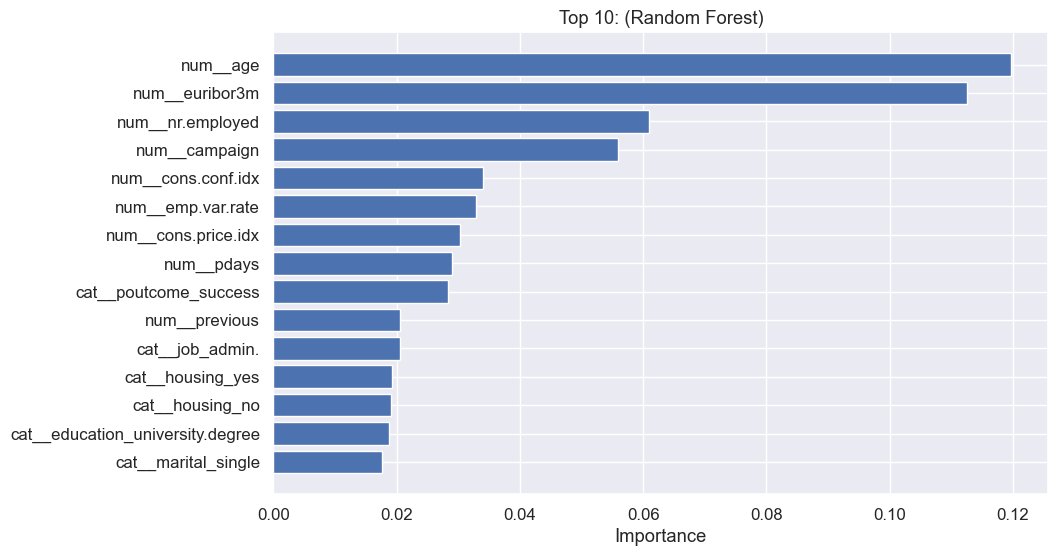

In [20]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import pandas as pd

# 1.Random Forest model to feature selection
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_train, y_train)


importances = rf_selector.feature_importances_
feature_names = X_train.columns

# 3. Create a dataframe
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# First 10 features
print("Top 10:")
print(feature_importance_df.head(10))

# Visualization
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'][:15][::-1], feature_importance_df['Importance'][:15][::-1])
plt.title('Top 10: (Random Forest)')
plt.xlabel('Importance')
plt.show()

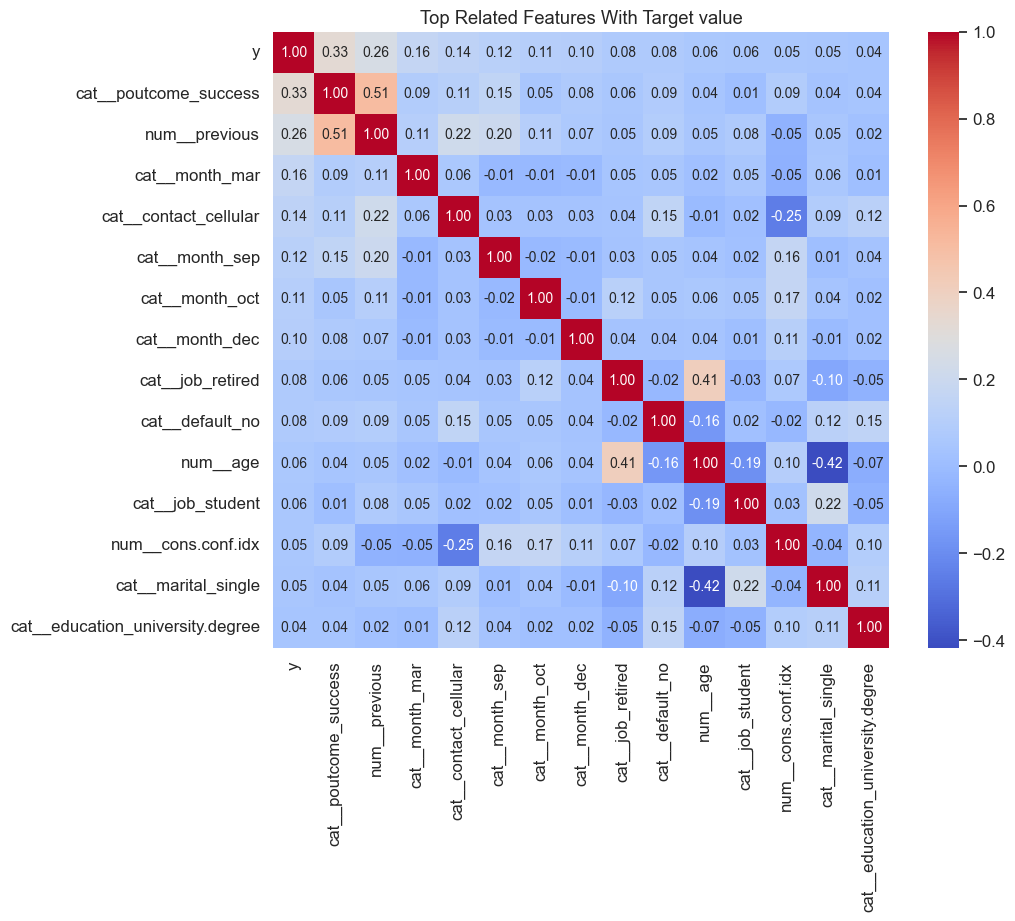

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# To catch correlation merge x and y
df_corr = X_processed_df.copy()
df_corr['y'] = y.values  # add target value

# 2. Calculate correlation matrix
correlation_matrix = df_corr.corr()


k = 15 #Top 15 Feature 
cols = correlation_matrix.nlargest(k, 'y')['y'].index
cm = np.corrcoef(df_corr[cols].values.T)

# 4. Visualization
plt.figure(figsize=(10, 8))
sns.set(font_scale=1.1)
hm = sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', 
                 annot_kws={'size': 10}, yticklabels=cols.values, xticklabels=cols.values, cmap="coolwarm")
plt.title('Top Related Features With Target value')
plt.show()

We can see a difference in the features in two figures. The reason is that random forest analyse the data by non-linear perspective while correlation matrix approaches with a linear perspective.

In [22]:



rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_train, y_train)


importances = rf_selector.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 2. (Threshold)
threshold = 0.005

# (Above the threshold)
selected_features = feature_importance_df[feature_importance_df['Importance'] >= threshold]['Feature'].tolist()
dropped_features = feature_importance_df[feature_importance_df['Importance'] < threshold]['Feature'].tolist()

print(f"Total Featres: {len(feature_importance_df)}")
print(f"Deleted Features: {len(dropped_features)}")
print(f"Current Features: {len(selected_features)}")

print("\nSome of deleted features:", dropped_features[:5])

# 3. Update the database
X_train_final = X_train[selected_features]
X_test_final = X_test[selected_features]

print("\nLow Impact Removal.")
X_train_final.shape
X_test_final.shape



Total Featres: 62
Deleted Features: 13
Current Features: 49

Some of deleted features: ['cat__job_entrepreneur', 'cat__job_self-employed', 'cat__month_nov', 'cat__month_apr', 'cat__job_housemaid']

Low Impact Removal.


(824, 49)

STEP 4

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import pandas as pd



# 1. Defining the Models
models = {

    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    # probability=True is required to calculate ROC-AUC 
    "SVM": SVC(kernel='rbf', probability=True, random_state=42)
}

results = []



# 2. Training and Evaluation Loop
for name, model in models.items():
    
    model.fit(X_train_final, y_train)
    

    y_pred = model.predict(X_test_final)                  # Class predictions (0 or 1)
    y_proba = model.predict_proba(X_test_final)[:, 1]     # Probability scores (0.0 to 1.0) for ROC-AUC
        

    # zero_division=0 handles cases where the model predicts no positives (Precision would be undefined)
    prec = precision_score(y_test, y_pred, zero_division=0) 
    rec = recall_score(y_test, y_pred)                      
    f1 = f1_score(y_test, y_pred)                           
    roc = roc_auc_score(y_test, y_proba)                    
    acc = accuracy_score(y_test ,y_pred)
    
 
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,     # Quality of the positive predictions
        "Recall": rec,         # Quantity of positives found (Critical for this project)
        "F1 Score": f1,        # Balance between Quality and Quantity
        "ROC-AUC": roc         # Model's ability to distinguish between classes generally
    })


results_df = pd.DataFrame(results).sort_values(by='F1 Score', ascending=False)

print("\n" + "="*60)
print("MODEL PERFORMANCE COMPARISON")
print("="*60)
print(results_df)
print("-" * 60)
print("Key Takeaways:")
print("• Recall is the most critical metric here (we don't want to miss potential clients).")
print("• If Accuracy is high but Recall is low, the model is biased towards the majority class ('no').")
print("• The model with the highest F1 Score/Recall should be selected for Hyperparameter Tuning.")



MODEL PERFORMANCE COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
1        Random Forest  0.899272   0.629630  0.188889  0.290598  0.747343
0  Logistic Regression  0.898058   0.650000  0.144444  0.236364  0.782576
2                  SVM  0.899272   0.769231  0.111111  0.194175  0.668074
------------------------------------------------------------
Key Takeaways:
• Recall is the most critical metric here (we don't want to miss potential clients).
• If Accuracy is high but Recall is low, the model is biased towards the majority class ('no').
• The model with the highest F1 Score/Recall should be selected for Hyperparameter Tuning.


STEP 5 AND 6


OPTIMIZED MODEL RESULTS (Post-Tuning)
Best Hyperparameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_split': 10, 'n_estimators': 300}
--------------------------------------------------
📊 Accuracy: 0.8811
   ↳ MEANING: Overall correctness. 

🎯 Precision: 0.4535
   ↳ MEANING: Out of all clients predicted as 'Subscriber', how many actually subscribed?
   ↳ IMPLICATION: Higher precision means fewer wasted calls/marketing efforts.

🔍 Recall (Sensitivity): 0.4333
   ↳ MEANING: Out of all actual subscribers, how many did the model correctly find?
   ↳ IMPORTANCE: This is critical for banks to avoid missing potential revenue.

⚖️ F1 Score: 0.4432
   ↳ MEANING: Harmonic mean of Precision and Recall. A balanced metric for imbalanced classes.


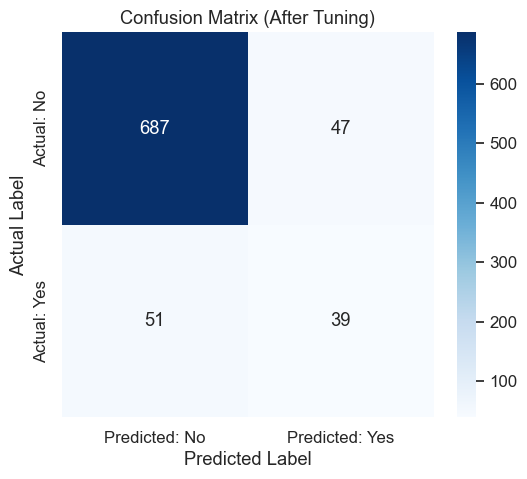

In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score, precision_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt



# 1. Defining the Parameter Grid
# We define a range of hyperparameters to test. The most critical parameter here
# is 'class_weight', which helps the model pay more attention to the minority class ('yes').
param_grid = {
    'n_estimators': [100, 200, 300],         # Number of trees in the forest.
    'max_depth': [10, 20, None],             # Max depth of the tree. Controls overfitting 
    'min_samples_split': [5, 10],            # Min samples required to split a node. Higher values prevent overfitting.
    'class_weight': ['balanced']             # CRITICAL: Adjusts weights inversely proportional to class frequencies.
                                             # This forces the model to treat 'yes' errors as more severe than 'no' errors.
}

# 2. Setting up GridSearchCV
# We use 'f1' as the scoring metric
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,            # 5-Fold Cross-Validation ensures the model generalizes well.
    scoring='f1',    # Optimization target: Balance between Precision and Recall.
    n_jobs=-1,       # Use all available CPU cores for faster computation.
    verbose=0        # Suppress output during training.
)



grid_search.fit(X_train_final, y_train)

best_rf_model = grid_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test_final)


# RESULTS & EVALUATION

print("\n" + "="*50)
print("OPTIMIZED MODEL RESULTS (Post-Tuning)")
print("="*50)
print(f"Best Hyperparameters: {grid_search.best_params_}")
print("-" * 50)

# Calculating Metrics
acc = accuracy_score(y_test, y_pred_tuned)
recall = recall_score(y_test, y_pred_tuned)
precision = precision_score(y_test, y_pred_tuned)
f1 = f1_score(y_test, y_pred_tuned)

# Detailed Interpretation for the Report
print(f"📊 Accuracy: {acc:.4f}")
print("   ↳ MEANING: Overall correctness. ")
print("")
print(f"🎯 Precision: {precision:.4f}")
print("   ↳ MEANING: Out of all clients predicted as 'Subscriber', how many actually subscribed?")
print("   ↳ IMPLICATION: Higher precision means fewer wasted calls/marketing efforts.")
print("")
print(f"🔍 Recall (Sensitivity): {recall:.4f}")
print("   ↳ MEANING: Out of all actual subscribers, how many did the model correctly find?")
print("   ↳ IMPORTANCE: This is critical for banks to avoid missing potential revenue.")
print("")
print(f"⚖️ F1 Score: {f1:.4f}")
print("   ↳ MEANING: Harmonic mean of Precision and Recall. A balanced metric for imbalanced classes.")
print("="*50)

# 5. Visualizing the Confusion Matrix
# This shows exactly where the model succeeds and fails (True Negatives vs False Negatives)
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted: No', 'Predicted: Yes'], 
            yticklabels=['Actual: No', 'Actual: Yes'])
plt.title('Confusion Matrix (After Tuning)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

Optimal Threshold Found: 0.4045

OPTIMIZED RESULTS WITH NEW THRESHOLD (0.40)
Old Recall: 0.4333  -->  New Recall: 0.5778
Old F1 Score: 0.4432  -->  New F1 Score: 0.4906
Precision: 0.4262
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.95      0.90      0.92       734
           1       0.43      0.58      0.49        90

    accuracy                           0.87       824
   macro avg       0.69      0.74      0.71       824
weighted avg       0.89      0.87      0.88       824



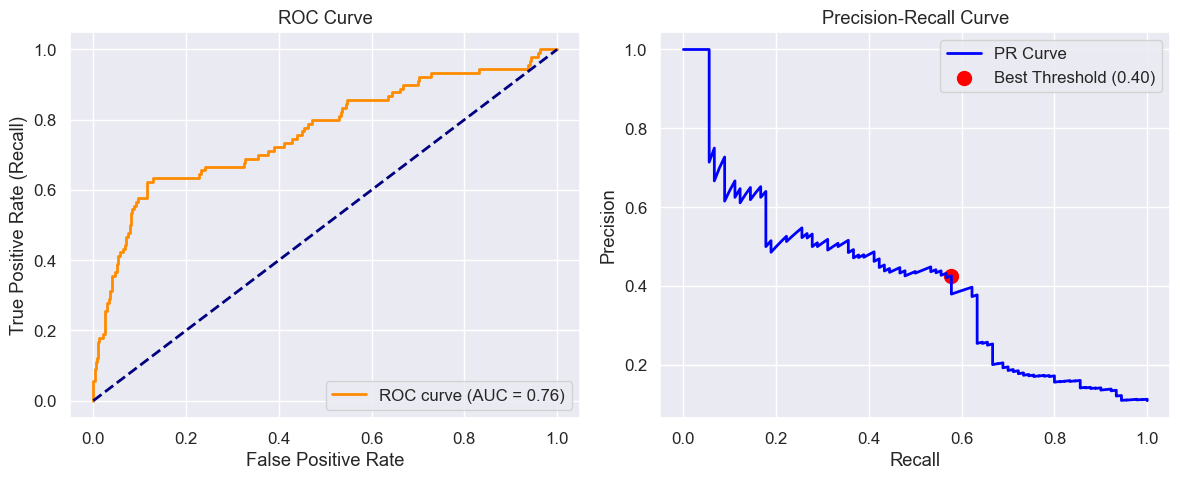

In [25]:
from sklearn.metrics import precision_recall_curve, roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt



# We are interested in the probability of class 1 ('Yes').
y_proba = best_rf_model.predict_proba(X_test_final)[:, 1]

# 2. Finding the Optimal Threshold
# precision_recall_curve calculates precision and recall for different threshold values.
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

# Calculating F1 Score for each threshold to find the sweet spot
# F1 = 2 * (Precision * Recall) / (Precision + Recall)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)

# Find the index of the maximum F1 score
best_threshold_index = np.argmax(f1_scores)
best_threshold = thresholds[best_threshold_index]

print(f"Optimal Threshold Found: {best_threshold:.4f}")

# 3. Making Predictions with the New Threshold
# If probability >= best_threshold, classify as 1, else 0.
y_pred_new = (y_proba >= best_threshold).astype(int)


print("\n" + "="*50)
print(f"OPTIMIZED RESULTS WITH NEW THRESHOLD ({best_threshold:.2f})")
print("="*50)


new_recall = recall_score(y_test, y_pred_new)
new_precision = precision_score(y_test, y_pred_new)
new_f1 = f1_score(y_test, y_pred_new)

# Comparison print for the report
print(f"Old Recall: 0.4333  -->  New Recall: {new_recall:.4f}")
print(f"Old F1 Score: 0.4432  -->  New F1 Score: {new_f1:.4f}")
print(f"Precision: {new_precision:.4f}")
print("-" * 50)
print(classification_report(y_test, y_pred_new))
print("="*50)



fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(12, 5))

# Plot 1: ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Diagonal line (Random guess)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)

# Plot 2: Precision-Recall Curve
plt.subplot(1, 2, 2)
plt.plot(recalls, precisions, color='blue', lw=2, label='PR Curve')
# Highlight the best threshold point
plt.scatter(recalls[best_threshold_index], precisions[best_threshold_index], 
            marker='o', color='red', s=100, label=f'Best Threshold ({best_threshold:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

STEP 7

In [26]:
import joblib



print("Saving model assets...")

# We pack everything into a single dictionary
model_assets = {
    'model': best_rf_model,              # The trained Random Forest (from Step 5)
    'preprocessor': preprocessor,        # The tool that converts text to numbers (Step 2)
    'selected_features': selected_features, # The list of 15 best features (Step 3)
    'threshold': best_threshold          # The optimal threshold we just found (Step 6)
}

# Save to a file
joblib.dump(model_assets, 'bank_model_assets.pkl')

print("\n" + "="*50)
print("Model saved as 'bank_model_assets.pkl'")
print("="*50)

Saving model assets...

Model saved as 'bank_model_assets.pkl'
